In [42]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [43]:
df=pd.read_csv("/content/drive/MyDrive/datasets/delivery_time_dataset.csv")

In [44]:
df.shape

(15000, 10)

In [45]:
df.describe()

,distance_km,order_hour,day_of_week,traffic_level,weather,vehicle_type,prep_time_min,num_items,rider_experience_yrs,delivery_time_min
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,6.459400,15.518000,3.016733,1.898467,0.522133,0.653933,20.016333,4.509267,3.985000,52.977933
std,3.440573,4.616105,2.015554,0.764589,0.699769,0.728793,9.970357,2.274407,2.582664,16.638931
min,1.000000,8.000000,0.000000,1.000000,0.000000,0.000000,5.000000,1.000000,0.000000,10.000000
25%,3.000000,11.000000,1.000000,1.000000,0.000000,0.000000,10.000000,3.000000,2.000000,41.000000
50%,6.000000,16.000000,3.000000,2.000000,0.000000,1.000000,20.000000,5.000000,4.000000,52.000000
75%,9.000000,20.000000,5.000000,2.000000,1.000000,1.000000,30.000000,6.000000,6.000000,64.000000
max,12.000000,23.000000,6.000000,3.000000,2.000000,2.000000,35.000000,8.000000,8.000000,110.000000


In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   distance_km           15000 non-null  int64
 1   order_hour            15000 non-null  int64
 2   day_of_week           15000 non-null  int64
 3   traffic_level         15000 non-null  int64
 4   weather               15000 non-null  int64
 5   vehicle_type          15000 non-null  int64
 6   prep_time_min         15000 non-null  int64
 7   num_items             15000 non-null  int64
 8   rider_experience_yrs  15000 non-null  int64
 9   delivery_time_min     15000 non-null  int64
dtypes: int64(10)
memory usage: 1.1 MB


In [47]:
df.isnull().sum()

,0
distance_km,0
order_hour,0
day_of_week,0
traffic_level,0
weather,0
vehicle_type,0
prep_time_min,0
num_items,0
rider_experience_yrs,0
delivery_time_min,0


In [48]:
df.duplicated().sum()

np.int64(1)

In [49]:
df=df.drop_duplicates()

In [50]:
df.duplicated().sum()

np.int64(0)

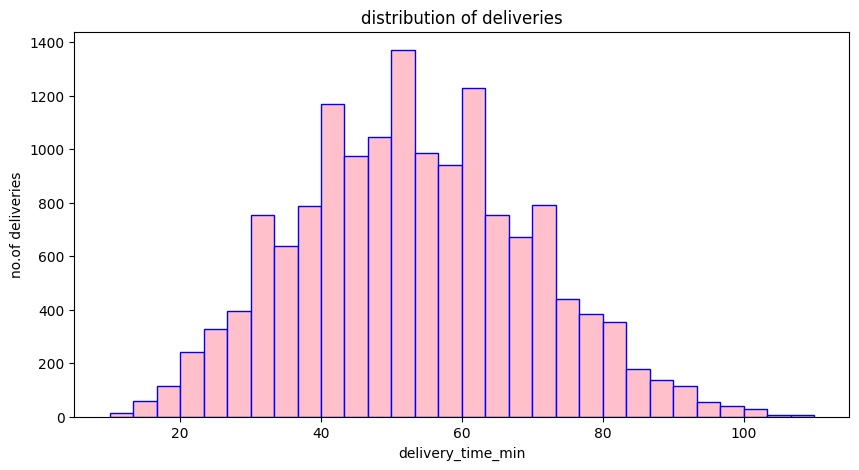

In [51]:
plt.figure(figsize=(10,5))
plt.hist(df["delivery_time_min"],bins=30,color="pink",edgecolor="blue")
plt.xlabel("delivery_time_min")
plt.ylabel("no.of deliveries")
plt.title("distribution of deliveries")
plt.show()

In [52]:
df.corr()["delivery_time_min"].sort_values(ascending=False)

,delivery_time_min
delivery_time_min,1.000000
distance_km,0.637209
prep_time_min,0.606442
traffic_level,0.301081
weather,0.203420
num_items,0.114923
day_of_week,0.062978
order_hour,0.033863
rider_experience_yrs,-0.043953
vehicle_type,-0.107847


In [53]:
X=df.drop("delivery_time_min",axis=1)
y=df["delivery_time_min"]
print(X.shape)
print(y.shape)

(14999, 9)
(14999,)


In [54]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=48)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(11999, 9)
(3000, 9)
(11999,)
(3000,)


In [55]:
model=DecisionTreeRegressor()
model.fit(X_train,y_train)

DecisionTreeRegressor()

In [56]:
y_pred=model.predict(X_test)
comparison=pd.DataFrame({
    "Actual_time":y_test.values[:10],
    "Predicted_time":y_pred[:10]
}).round(1)

print(comparison)

   Actual_time  Predicted_time
0           37            34.0
1           47            40.0
2           46            38.0
3           72            79.0
4           80            68.0
5           56            63.0
6           70            72.0
7           59            56.0
8           38            41.0
9           66            71.0


In [57]:
mae=mean_absolute_error(y_test,y_pred)
rms=np.sqrt(mean_squared_error(y_test,y_pred))
r2=r2_score(y_test,y_pred)

print(f"MAE:{mae:.1f}minutes")
print(f"RMS:{rms:.1f}minutes")
print(f"r2:{r2:.3f}")


MAE:3.9minutes
RMS:4.9minutes
r2:0.912


In [58]:
importance=pd.Series(model.feature_importances_,index=X.columns)
importance.round(3)

,0
distance_km,0.416
order_hour,0.018
day_of_week,0.011
traffic_level,0.095
weather,0.046
vehicle_type,0.026
prep_time_min,0.362
num_items,0.017
rider_experience_yrs,0.010


In [59]:
new_order = pd.DataFrame([{
    'distance_km':7 ,
    'order_hour':20,
    'day_of_week': 5,
    'traffic_level':3 ,
    'weather':1 ,
    'vehicle_type':1 ,
    'prep_time_min': 20,
    'num_items': 4,
    'rider_experience_yrs': 2
}])

predicted = model.predict(new_order)[0]
print(f'Predicted delivery time: {predicted:.0f} minutes')

Predicted delivery time: 64 minutes


In [60]:
import joblib
joblib.dump(model,"delivery_time_model.pkl")

['delivery_time_model.pkl']